# Historical JC-phase CD study

This study is retained for its derivations. Its small same-duration fidelity gain is not a current recommendation. Current pulse-spacing plots are in the [CD notebook](fast_conditional_displacement.ipynb) and [conditional-squeezing notebook](conditional_gaussian_gates.ipynb).

For **CD beta=1**, smooth phase control gives a modest fidelity gain at the
same **370 ns**: 99.2278% with the original fixed pump, 99.3052% with mirrored
phase control, and 99.3575% after relaxing that symmetry and applying one
explicit final qubit Z frame. **No shorter tested construction reached 99%.**

All accepted scores are coherent process fidelity on qubit g/e times Fock
n=0..8. The target and output cutoffs are independently converged; leakage
and relative phases count. The qubit is ideal and two-level. The programmed
sideband radius is constant, with outer 5 ns ramps. Every phase change follows
a 10 ns quintic circular arc centered on a qubit-envelope zero; every physical
qubit envelope remains at least 30 ns. Peak played coupling respects the
200 ns minimum vacuum-swap time.

The independently specified target and acceptance score are

$$U_{\rm CD}(\beta)=e^{\beta\sigma_x(a^\dagger-a)},\qquad
F_{\rm proc}=|\operatorname{Tr}(T^\dagger V)|^2/18^2.$$

This notebook separates formal cancellation from observed gate fidelity. Its
purpose is to show what the optimizer changed, which strategic ideas failed,
and exactly what the small accepted improvement does and does not establish.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['OMP_NUM_THREADS']='1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from project_paths import ROOT
import cd_trains as cd
import hardware_check as hw
from notebook_figures import read,certificate,drives,waveform_figure,finish,DATA
from phase_arc_cd import symbol
names=['cd_constant_reference','arc_free_n10_all5_1','central_arc_gap50_half3_word0',
       'arc_sym_n12_magnus4','arc_lifted_n12']
records=[certificate(n) for n in names]
assert all(r['strength']==1 and r['columns']==18 and r['peak_swap_ns']>=200 for r in records)
new=[r for r in records if r['name']!='cd_constant_reference']
assert len(new)==4 and sum(r['complex_amplitudes'] for r in new)==13824
assert max(r['independent_max_difference'] for r in new)<1e-10
print('INDEPENDENT PHASE STUDY:4 waveforms;72 input columns;13824 complex amplitudes')
display(pd.DataFrame([{k:r[k] for k in ['name','command_us','fidelity','worst_basis_fidelity','qubit_frame_Rz','peak_swap_ns']} for r in records]))


INDEPENDENT PHASE STUDY:4 waveforms;72 input columns;13824 complex amplitudes


,name,command_us,fidelity,worst_basis_fidelity,qubit_frame_Rz,peak_swap_ns
0,cd_constant_reference,0.370,0.992278,0.979996,0.000000,281.332152
1,arc_free_n10_all5_1,0.355,0.985003,0.954230,0.000000,265.384095
2,central_arc_gap50_half3_word0,0.360,0.976496,0.943453,0.000000,236.683742
3,arc_sym_n12_magnus4,0.370,0.993052,0.980839,0.000000,266.489632
4,arc_lifted_n12,0.370,0.993575,0.980955,-0.070395,266.784890


## 1. Compare the same target before discussing speed

Every point below targets the same beta=1 unitary. The shorter candidates
were independently replayed and rejected. Changing coupling while allowing
under-displacement is not a speed comparison.

The mirrored construction varies six qubit axes, six pump phases and one
constant coupling. Its second half is the inverse time reverse of the qubit
path, with the pump phase mirrored. Low-order first/cubic moments supply the
initial guesses; the final optimization uses the complete packed/RFDC
waveform and all 18 target columns.

The mirrored finite controls satisfy

$$q(T-t)=-q(t),\qquad s(T-t)=s(t),$$

so the qubit-only operation closes and the interaction-frame Hamiltonian is
time symmetric. This removes the second Magnus term.

The relaxed refinement starts from that solution and allows all twelve axes
and pump phases to vary separately. It also allows one final qubit Z frame.
It is a compiled local refinement, not a claimed fourth-order product formula.
Neither optimization fits individual waveform samples.

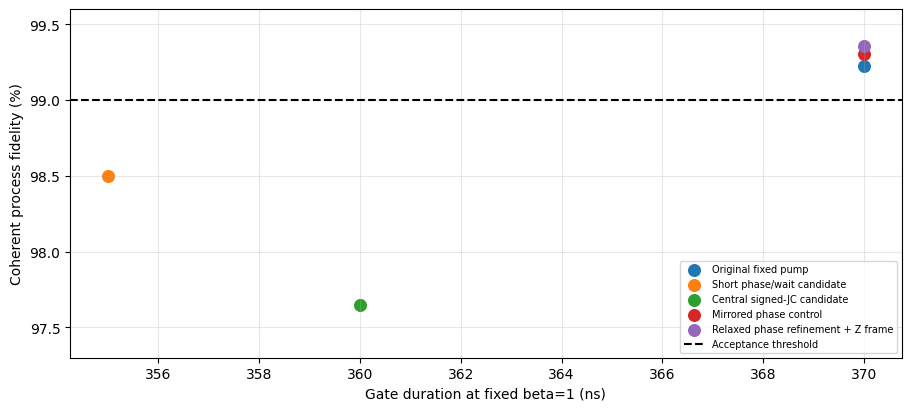

No independently accepted phase-control point is faster than370ns.


In [2]:

labels=['Original fixed pump','Short phase/wait candidate','Central signed-JC candidate',
        'Mirrored phase control','Relaxed phase refinement + Z frame']
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for i,(r,label) in enumerate(zip(records,labels)):
    ax.scatter(r['command_us']*1000,100*r['fidelity'],s=70,label=label)
ax.axhline(99,c='k',ls='--',label='Acceptance threshold')
ax.set(xlabel='Gate duration at fixed beta=1 (ns)',ylabel='Coherent process fidelity (%)',ylim=(97.3,99.6))
ax.grid(alpha=.3);ax.legend(fontsize=7,loc='lower right');finish('phase_cd_fixed_target_comparison')
print('No independently accepted phase-control point is faster than370ns.')


## 2. A corrected Magnus conclusion: the complete reference cancels second order

The earlier small nonzero second-order term came from an isolated flat-window
Hann word. A fresh quantum derivative of the **complete reference including
its ramps and zero padding** gives a second-order norm of 5.44e-16 after
factoring out g squared. Its qubit-odd and pump-even reflection centers align
once the sample origin is accounted for. The complete reference already
cancels second order. Its small unwanted first-order ramp force remains.

For a fixed pump and X-only controls, cancelling the first transverse moment
leaves a longitudinal principal cubic coefficient

$$c_3=-\frac14\int_0^T\left|\int_0^t e^{i\theta(s)}\,ds\right|^2dt.$$

A phase trajectory changes these assumptions and can introduce other cubic
terms. We tested mirrored phase geometry, signed JC plateaus, full local
windings, rectified X/Y paths, fractional rotations, waits and pair removal.
The catalogue contains 14,256 local-winding paths, and the X/Y screen contains
1,980 qubit words and 3,204 moment paths. Whole-waveform simulation rejects the
shorter selected candidates.

The plots below compare formal generator coefficients, **not fidelities**.
The accepted mirrored phase gate has a slightly larger total principal cubic
norm than the reference. Its small fidelity gain therefore does not prove
cancellation of the dominant cubic error. At finite coupling, low-order terms
alone do not predict the full gate score.

A separate finite-coupling error-log diagnostic at 64,96,128 oscillator
levels supports this caution: a Hermitian polynomial basis through oscillator
degree three leaves about68% of the reference generator norm and63% of the
refined gate's generator norm unexplained. These are fit residuals, not
infidelities. The fitted coefficients are stable across the larger cutoffs;
small matrix-log output tails converge more slowly. This diagnostic does not
establish that one cubic operator dominates the working gate. Its complete
counts and residuals are in [the error analysis](../runs/phase_arc_cd/finite_gate_error.json).

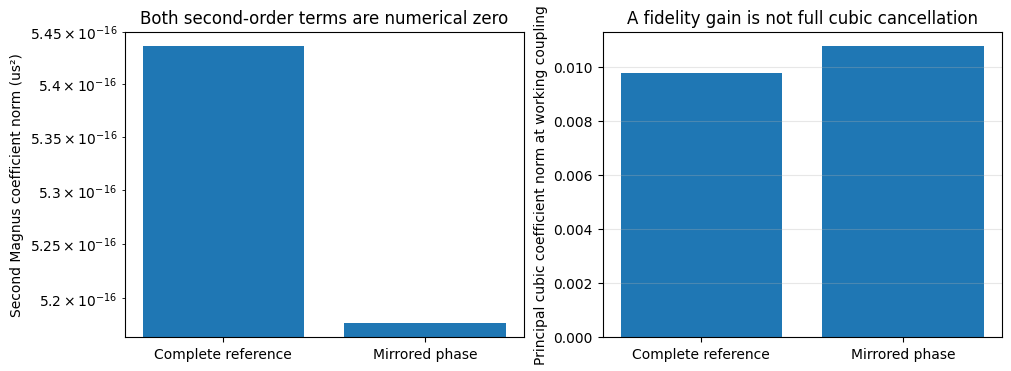

Independent quantum checks:256 first-order amplitudes;24 principal cubic coefficients


,name,exact_second_norm,first_max_error,third_max_error
0,cd_constant_reference,5.436690e-16,1.782685e-12,6.242124e-11
1,arc_sym_n12_magnus4,5.176892e-16,5.953232e-09,5.908320e-11


In [3]:

quantum=read('runs/phase_arc_cd/whole_gate_magnus_check.json')
assert len(quantum)==2
assert max(r['third_max_error'] for r in quantum)<1e-8
values=[]
for name in ['cd_constant_reference','arc_sym_n12_magnus4']:
    r=certificate(name);raw=np.load(ROOT/r['controls_file']);A,B,C3=symbol(raw['q'],raw['s'],32)
    values.append(dict(name=name,first=A,second=np.linalg.norm(B),principal_cubic=np.linalg.norm(C3)))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),constrained_layout=True)
axes[0].bar(['Complete reference','Mirrored phase'],[r['exact_second_norm'] for r in quantum])
axes[0].set(yscale='log',ylabel='Second Magnus coefficient norm (us²)',title='Both second-order terms are numerical zero')
axes[1].bar(['Complete reference','Mirrored phase'],[r['principal_cubic'] for r in values])
axes[1].set(ylabel='Principal cubic coefficient norm at working coupling',title='A fidelity gain is not full cubic cancellation')
for ax in axes:ax.grid(axis='y',alpha=.3)
finish('phase_cd_magnus_and_fidelity_distinction')
print('Independent quantum checks:256 first-order amplitudes;24 principal cubic coefficients')
display(pd.DataFrame([{k:r[k] for k in ['name','exact_second_norm','first_max_error','third_max_error']} for r in quantum]))


## 3. Literal sequence and the actual IQ waveform

The mirrored gate uses a six-pulse first half. Replay the inverse qubit
rotations in reverse order, reversing the actual envelope samples too. Mirror
the pump trajectory. The full [mirrored pulse table](../runs/research_verified/arc_sym_n12_magnus4_pulses.csv)
and [phase-arc recipe](../runs/phase_arc_cd/arc_sym_n12_magnus4_recipe.json) specify
all axes and transition times. It gives 99.3052% without a final qubit frame.

The slightly higher-fidelity relaxed gate shown below has the complete
[12-pulse table](../runs/research_verified/arc_lifted_n12_pulses.csv),
[phase-arc recipe](../runs/phase_arc_cd/arc_lifted_n12_recipe.json) and
[exact SDK words](../runs/research_verified/arc_lifted_n12_words.npz). Apply the
single declared final rotation

$$R_z(\varphi)=e^{-i\varphi\sigma_z/2},\qquad\varphi=-0.0703951276\;\mathrm{rad}.$$

That tracked frame is included in its 99.3575% coherent score. It is not an
unaccounted physical 30 ns pulse. No cavity frame is fitted.

I/Q follow a circle, not a straight Cartesian blend. The programmed magnitude
is constant on the plateau. The RFDC produces small magnitude ripple, which is
included in propagation and in the peak-coupling test. The IQ plot removes
only the common display latency; simulation retains the full filter tail.

,pulse,start_ns,duration_ns,rotation_pi_units,qubit_DAC_deg,reversed_envelope
0,1,5.0,30.0,1.0,351.519956,False
1,2,35.0,30.0,1.0,339.216773,False
2,3,65.0,30.0,1.0,165.542910,False
3,4,95.0,30.0,1.0,182.050805,False
4,5,125.0,30.0,1.0,344.907734,False
5,6,155.0,30.0,1.0,303.926010,False
6,7,185.0,30.0,1.0,123.048469,False
7,8,215.0,30.0,1.0,165.618465,False
8,9,245.0,30.0,1.0,6.872843,False
9,10,275.0,30.0,1.0,349.222023,False


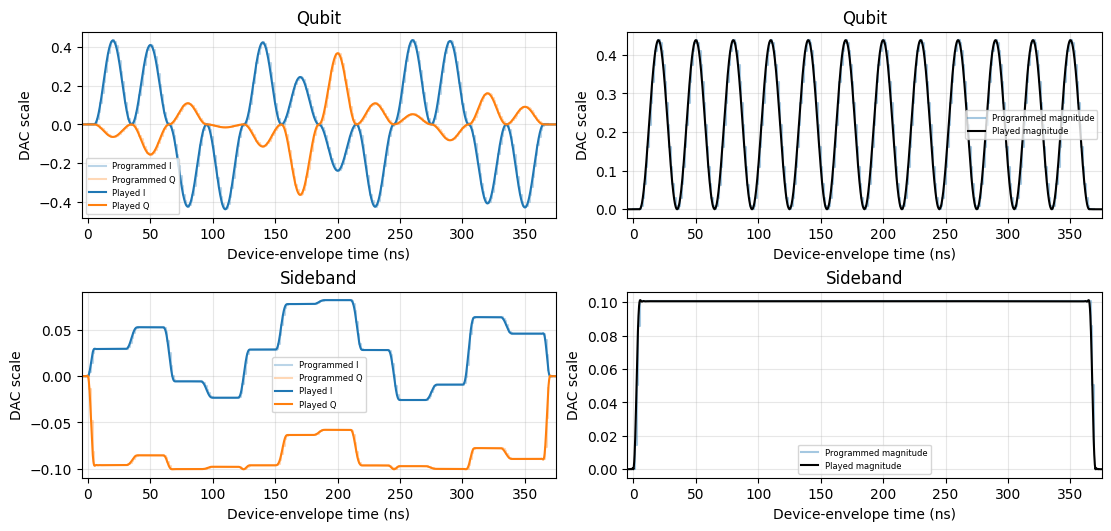

ARC CHECK:11 centers;max played qubit amplitude at those centers 0.0
Played plateau magnitude relative to median: 0.9996394600758796 1.0004566180327863
Strongest played coupling corresponds to swap(ns): 266.7848901255828


In [4]:

display(pd.read_csv(DATA/'arc_lifted_n12_pulses.csv'))
waveform_figure('arc_lifted_n12');finish('phase_cd_literal_best_IQ')
r=certificate('arc_lifted_n12');meta=read(r['recipe_file']);q,s,qf,sf,w=drives(r['name'])
delay=np.argmax(abs(hw.rfdc_interpolate(np.array([1.]))))
centers=[8*a['center_sample']+delay for a in meta['phase_arcs']]
assert len(centers)==11 and max(abs(qf[centers]))<1e-12
lo,hi=delay+8*8,delay+8*(len(s)-8)
radius=np.median(abs(sf[lo:hi]))
print('ARC CHECK:11 centers;max played qubit amplitude at those centers',max(abs(qf[centers])))
print('Played plateau magnitude relative to median:',min(abs(sf[lo:hi]))/radius,max(abs(sf[lo:hi]))/radius)
print('Strongest played coupling corresponds to swap(ns):',r['peak_swap_ns'])


## 4. Does the phase pattern scale to other beta values?

This is a separate target-scaling test, not a same-beta strength plot. Keep
the entire internal phase pattern and 370 ns duration fixed. Vary only the
constant coupling and, in the corrected column, two global carrier-axis
shifts. Every row still compares all 18 inputs with its independently
specified exact beta target.

The uncorrected simple amplitude scaling already exceeds 99% at the checked
beta=0.25,0.5,0.75,1 points. Fitting only the two global axes and one gain
improves these scores. Their shifts approximately follow the expected
beta-squared trend from linear/cubic mixing; this is a calibration heuristic,
not proof of cancellation or an untested fidelity guarantee. At beta=1.25,
the same-duration gate fails 99% even after correction. Do not extrapolate it.
For a broadly checked, simpler fast scaling recipe, use the original
[fixed-sideband CD notebook](fast_conditional_displacement.ipynb).

These scaling rows are SDK/RFDC simulations at 64 output levels; only the
beta=1 gate has the separate full convergence certificate used above.

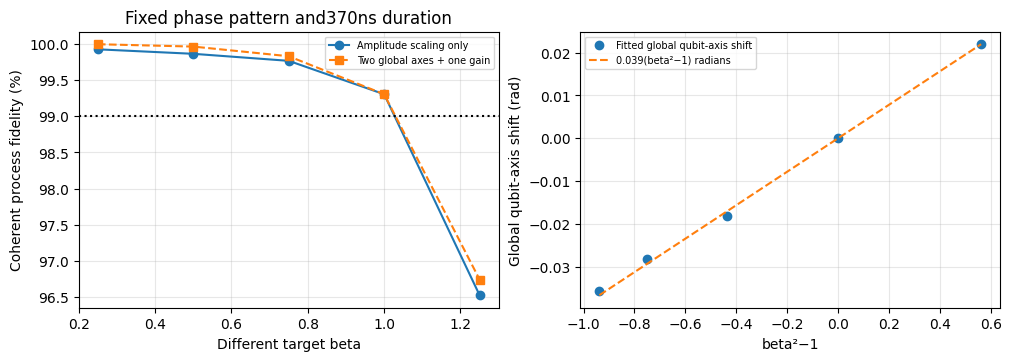

,beta,initial_fidelity,fidelity,parameters,evaluations
0,0.25,0.999265,0.999971,"[-0.035629178377478435, 0.0007409029166410128,...",109
1,0.50,0.998644,0.999643,"[-0.028051976032133878, 0.0010050988625627802,...",64
2,0.75,0.997672,0.998309,"[-0.018133096773462556, 0.0005555381119165178,...",115
3,1.00,0.993052,0.993052,"[6.005847365548667e-05, -1.5758532642795586e-0...",24
4,1.25,0.965262,0.967427,"[0.02189491775513162, -0.0013104101545739987, ...",94


SCALING CHECK:5 exact targets; 7308 input-column evaluations


In [5]:

scaling=pd.DataFrame(read('runs/phase_cd_scaling/results.json'))
assert len(scaling)==5 and scaling.columns.is_unique
assert scaling.iloc[-1].fidelity<.99
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
axes[0].plot(scaling.beta,100*scaling.initial_fidelity,'o-',label='Amplitude scaling only')
axes[0].plot(scaling.beta,100*scaling.fidelity,'s--',label='Two global axes + one gain')
axes[0].axhline(99,c='k',ls=':');axes[0].set(xlabel='Different target beta',ylabel='Coherent process fidelity (%)',title='Fixed phase pattern and370ns duration')
axes[0].legend(fontsize=7)
shifts=np.array(scaling.parameters.to_list())[:,0]
axes[1].plot(scaling.beta**2-1,shifts,'o',label='Fitted global qubit-axis shift')
axes[1].plot(scaling.beta**2-1,.039*(scaling.beta**2-1),'--',label='0.039(beta²−1) radians')
axes[1].set(xlabel='beta²−1',ylabel='Global qubit-axis shift (rad)');axes[1].legend(fontsize=7)
for ax in axes:ax.grid(alpha=.3)
finish('phase_cd_scaling_limits')
display(scaling[['beta','initial_fidelity','fidelity','parameters','evaluations']])
print('SCALING CHECK:5 exact targets;',18*int(scaling.evaluations.sum()),'input-column evaluations')


## 5. Fresh independent replay and the research decision

The certificates independently compare all 18 columns at converged cutoffs.
This cell replays the relaxed gate again at 128 oscillator levels and compares
complex amplitudes with its saved certificate. Basis-state fidelity is shown
as a diagnostic and is not the acceptance metric.

The phase branch gives a real but modest fidelity improvement at the same
370 ns. It has not supplied a shorter 99% gate or a demonstrated cancellation
of the whole dominant cubic operator. The fixed pump remains the simpler
experimental choice. This finite search does not establish a global speed
limit. Counts, rejected hypotheses and the correction to the earlier
second-order statement are recorded in [WORK_STATUS](../WORK_STATUS.md).

FRESH PHASE CD CHECK:18 columns; 4608 complex amplitudes;max difference 1.002958247892506e-15 F 0.993574864995144


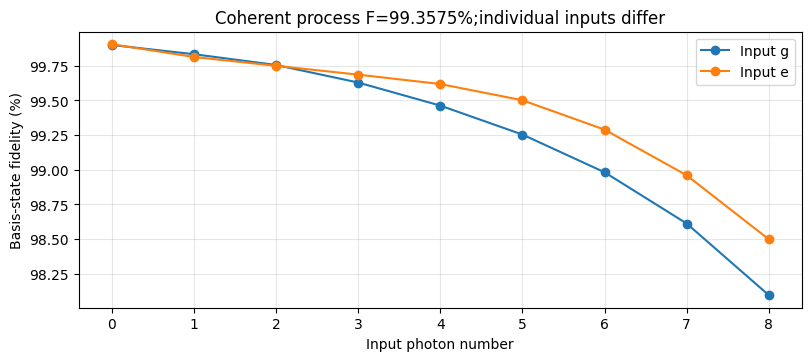

In [6]:

r=certificate('arc_lifted_n12');q,s,qf,sf,w=drives(r['name'])
space=cd.Space(128,9);initial=np.eye(256,dtype=complex)[:,space.inputs]
V=hw.propagate(qf,sf,initial,cd.DT/8,order=16)
V*=np.exp(-1j*r['qubit_frame_Rz']*space.z/2)[:,None]
T=cd.target_columns(space,'cd',1.)
saved=np.load(DATA/(r['name']+'_columns.npz'))['output'];pad=np.zeros_like(V);pad[:len(saved)]=saved
error=float(np.max(abs(V-pad)));F=float(abs(np.vdot(T,V)/18)**2)
assert V.shape==(256,18) and error<1e-10 and abs(F-r['fidelity'])<1e-12
print('FRESH PHASE CD CHECK:18 columns;',V.size,'complex amplitudes;max difference',error,'F',F)
overlap=np.sum(T.conj()*V,axis=0)
fig,ax=plt.subplots(figsize=(8,3.5),constrained_layout=True)
for offset,label in [(0,'Input g'),(9,'Input e')]:ax.plot(np.arange(9),100*abs(overlap[offset:offset+9])**2,'o-',label=label)
ax.set(xlabel='Input photon number',ylabel='Basis-state fidelity (%)',title=f'Coherent process F={100*F:.4f}%;individual inputs differ')
ax.grid(alpha=.3);ax.legend();finish('phase_cd_independent_all_inputs')
